### Setup

These cells are copied unchanged from `exam2.ipynb`: the imports, the Black–Scholes functions and sample data of §1.4, the simulation code of §1.6–§1.8, and the Monte Carlo pricer `mc_price` of §2.3. Run them before the Results below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from scipy.stats import binom


In [2]:
def _d1_d2(S, K, T, r, sigma):
    # d1 and d2 as in §1.4 (Lecture 1, p.43). np.log / np.sqrt rather than math.*, so that
    # S, sigma, T and r may be arrays when the data are varied in the parameter studies.
    sqrtT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrtT)
    return d1, d1 - sigma * sqrtT


def bs_price(S, K, T, r, sigma, kind='call'):
    '''
    S: spot price
    K: strike price
    T: time to expiry T - t (in years)
    r: risk-free interest rate (annualized)
    sigma: volatility (annualized)
    kind: 'call' or 'put'
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    disc_K = K * np.exp(-r * T)                    # present value of the strike
    if kind == 'call':
        return S * norm.cdf(d1) - disc_K * norm.cdf(d2)
    if kind == 'put':
        return disc_K * norm.cdf(-d2) - S * norm.cdf(-d1)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def bs_greeks(S, K, T, r, sigma, kind='call'):
    '''
    Analytic Black-Scholes greeks, the benchmark for the Monte Carlo greeks.
    Returns dict(delta, gamma, vega, theta, rho), each per unit change: vega per 1.00 of sigma,
    rho per 1.00 of r, theta per year. Theta is dV/dt, so it is negative for a call.
    '''
    d1, d2 = _d1_d2(S, K, T, r, sigma)
    sqrtT, disc_K, pdf = np.sqrt(T), K * np.exp(-r * T), norm.pdf(d1)
    gamma = pdf / (S * sigma * sqrtT)              # same for call and put
    vega = S * sqrtT * pdf                         # same for call and put
    decay = -sigma * S * pdf / (2 * sqrtT)         # theta term shared by call and put
    if kind == 'call':
        return dict(delta=norm.cdf(d1), gamma=gamma, vega=vega,
                    theta=decay - r * disc_K * norm.cdf(d2),
                    rho=T * disc_K * norm.cdf(d2))
    if kind == 'put':
        return dict(delta=norm.cdf(d1) - 1, gamma=gamma, vega=vega,
                    theta=decay + r * disc_K * norm.cdf(-d2),
                    rho=-T * disc_K * norm.cdf(-d2))
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


def payoff(ST, K, kind='call'):
    # Vanilla payoff at expiry: max(S_T - K, 0) for a call, max(K - S_T, 0) for a put.
    if kind == 'call':
        return np.maximum(ST - K, 0.0)
    if kind == 'put':
        return np.maximum(K - ST, 0.0)
    raise ValueError(f"kind must be 'call' or 'put', got {kind!r}")


In [3]:
# Sample data from the exam brief (K = strike, T = time to expiry T - t)
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20

d1, d2 = _d1_d2(S0, K, T, r, sigma)
C, P = bs_price(S0, K, T, r, sigma, 'call'), bs_price(S0, K, T, r, sigma, 'put')


def p_tilde(S_prime, S, T, r, sigma):
    # Risk-neutral lognormal transition density of S_T = S_prime, given S_t = S (§1.3)
    bracket = np.log(S / S_prime) + (r - 0.5 * sigma**2) * T
    return np.exp(-bracket**2 / (2 * sigma**2 * T)) / (sigma * S_prime * np.sqrt(2 * np.pi * T))


# For each option: the payoff, and the range of S' where it is non-zero (§1.4)
contracts = {'call': (lambda s: s - K, K, np.inf),
             'put':  (lambda s: K - s, 0.0, K)}

rows = {}
for kind, (pay, lower, upper) in contracts.items():
    expected, _ = quad(lambda s: p_tilde(s, S0, T, r, sigma) * pay(s), lower, upper)
    rows[kind] = {
        'E^Q[payoff], integral': expected,
        'price, discounted integral': np.exp(-r * T) * expected,
        'price, closed form': bs_price(S0, K, T, r, sigma, kind),
    }

benchmark = pd.DataFrame(rows).T
benchmark['difference'] = benchmark['price, discounted integral'] - benchmark['price, closed form']

print(f"Black-Scholes closed form:   call C = {C:.4f}   put P = {P:.4f}\n")
print(f"d1 = {d1:.4f}   d2 = {d2:.4f}   N(d1) = {norm.cdf(d1):.5f}   N(d2) = {norm.cdf(d2):.5f}\n")
print(benchmark.to_string(float_format=lambda x: f'{x:.6f}' if abs(x) > 1e-4 else f'{x:.1e}'))
print(f"\nPut-call parity:  C - P = {C - P:.6f}   S - K e^(-rT) = {S0 - K * np.exp(-r * T):.6f}")


Black-Scholes closed form:   call C = 10.4506   put P = 5.5735

d1 = 0.3500   d2 = 0.1500   N(d1) = 0.63683   N(d2) = 0.55962

      E^Q[payoff], integral  price, discounted integral  price, closed form  difference
call              10.986396                   10.450584           10.450584     3.6e-15
put                5.859287                    5.573526            5.573526    -1.8e-15

Put-call parity:  C - P = 4.877058   S - K e^(-rT) = 4.877058


In [4]:
SEED = 1995                                        

#K, S0, r, sigma, T defined already in sample data above 

# payoff(ST, K, kind) is defined with the Black-Scholes functions in §1.4


def simulate_terminal_exact(S0, r, sigma, T, n_paths, rng): #GBM assumptions one step simulation to maturity #S_T = S_0 · exp((r − σ²/2)T + σ√T · Z),Z ~ N(0,1)
    phi = rng.standard_normal(n_paths)
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * phi)


def mc_price_from_ST(ST, K, T, r, kind='call'): #MC payoff determined from payoff across average of terminal stock prices, discounted to present value
                                                 #standard error equal to sample standard deviation from the mean / sqrt(N)
    Y = np.exp(-r * T) * payoff(ST, K, kind)
    return Y.mean(), Y.std(ddof=1) / np.sqrt(Y.size)


In [5]:
def euler_paths(S0, r, sigma, T, Z):
    # Euler-Maruyama (§1.8): S_{n+1} = S_n + r S_n dt + sigma S_n dW_n.
    # Z holds the standard normal draws: one row per path, one column per time step.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z                                  # Brownian increments, variance dt
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):                              # loop over time; every path moves at once
        S[:, n + 1] = S[:, n] + r * S[:, n] * dt + sigma * S[:, n] * dW[:, n]
    return S


In [6]:
def milstein_paths(S0, r, sigma, T, Z):
    # Milstein (§1.8): the Euler step plus the Ito-Taylor term 1/2 b b' (dW^2 - dt),
    # which for geometric Brownian motion (b = sigma S, b' = sigma) is 1/2 sigma^2 S_n (dW_n^2 - dt).
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    dW = np.sqrt(dt) * Z
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    for n in range(n_steps):
        Sn, dWn = S[:, n], dW[:, n]
        S[:, n + 1] = Sn + r * Sn * dt + sigma * Sn * dWn + 0.5 * sigma**2 * Sn * (dWn**2 - dt)
    return S


In [7]:
def exact_paths(S0, r, sigma, T, Z):
    # Exact solution of geometric Brownian motion (§1.8): ln S moves by (r - sigma^2/2) dt + sigma dW
    # on every step, whatever the step size, so add up the log-steps along each path and exponentiate.
    n_paths, n_steps = Z.shape
    dt = T / n_steps
    log_paths = np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1)
    return np.hstack([np.full((n_paths, 1), S0), S0 * np.exp(log_paths)])


In [8]:
SCHEMES = {'euler': euler_paths, 'milstein': milstein_paths, 'exact': exact_paths}


def simulate_paths(S0, r, sigma, T, n_steps, n_paths, rng, scheme='euler', Z=None):
    # Single entry point for the pricing code: draw the normals from the seeded generator
    # (unless Z is supplied, e.g. -Z for antithetic paths), then run the chosen scheme.
    # Returns an array of shape (n_paths, n_steps + 1); column 0 is S0.
    if scheme not in SCHEMES:
        raise ValueError(f"scheme must be one of {list(SCHEMES)}, got {scheme!r}")
    if Z is None:
        Z = rng.standard_normal((n_paths, n_steps))
    return SCHEMES[scheme](S0, r, sigma, T, Z)


In [9]:
import time


def mc_price(S0, K, T, r, sigma, n_paths, n_steps, scheme, kind, rng, antithetic=False):
    # Monte Carlo price and standard error (§1.6), with or without antithetic variates (§1.9).
    # n_paths counts every simulated path, so plain and antithetic runs of the same n_paths cost the same.
    # Returns (price, SE).
    if not antithetic:
        paths = simulate_paths(S0, r, sigma, T, n_steps, n_paths, rng, scheme)
        discounted_payoffs = np.exp(-r * T) * payoff(paths[:, -1], K, kind)       # one per path
    else:
        n_pairs = n_paths // 2
        Z_pairs = rng.standard_normal((n_pairs, n_steps))                         # one set of draws per pair
        paths_plus = simulate_paths(S0, r, sigma, T, n_steps, n_pairs, rng, scheme, Z=Z_pairs)
        payoffs_plus = payoff(paths_plus[:, -1], K, kind)                         # payoff on each path
        del paths_plus                                                            # free memory before the mirror run
        paths_minus = simulate_paths(S0, r, sigma, T, n_steps, n_pairs, rng, scheme, Z=-Z_pairs)
        payoffs_minus = payoff(paths_minus[:, -1], K, kind)                       # payoff on its mirror image
        discounted_payoffs = np.exp(-r * T) * 0.5 * (payoffs_plus + payoffs_minus)   # one average per pair
    price = discounted_payoffs.mean()
    standard_error = discounted_payoffs.std(ddof=1) / np.sqrt(discounted_payoffs.size)   # over paths, or over pairs
    return price, standard_error


### 2.4 Greeks and varying the data: volatility, interest rate, spot and maturity


**What we measure, and against what.** We now vary the data and study the greeks. Monte Carlo
gives a price at one point, not its slopes, so each greek needs extra work (§1.7; Lecture 4, pp.14–15). We
estimate the greeks in three ways and compare each with the analytic Black–Scholes greeks of §1.4 (`bs_greeks`;
Lecture 1, pp.56–73). All use the exact one-step scheme, antithetic pairs and $N = 100{,}000$ paths per price.

- **Bump and revalue** (`mc_greeks`): reprice with one input nudged up and down and take the central
  difference, for example $\hat\Delta = [\hat V(S_0+h) - \hat V(S_0-h)]/2h$ (Lecture 4, pp.24–28). Five greeks
  cost nine prices.
- **Common random numbers (CRN)**: every revaluation reuses the same draws $\phi$. We also run without them,
  for comparison.
- **Bump-free estimators**: the pathwise delta differentiates the
  payoff along each simulated path before averaging. The likelihood-ratio gamma instead weights the payoff
  using derivatives of the simulated price density, avoiding a finite price bump.

The standard error of each estimator is the spread of its value over $M = 100$ seeds.

| Question | Where |
|---|---|
| How accurate are the greeks at the sample data, with and without CRN? | Table 2.4a |
| Do they satisfy the Black–Scholes equation, $\Theta + \tfrac12\sigma^2S^2\Gamma + rS\Delta - rV = 0$ (Lecture 1, p.66)? | printed with Table 2.4a |
| How should the bump size $h$ be chosen? | Figure 2.4a |
| **Varying the data:** do the prices and greeks follow Black–Scholes as $S_0$, $\sigma$, $T - t$ and $r$ move over wide ranges? | Figures 2.4b and 2.4c |


In [10]:
def mc_greeks(S0, K, T, r, sigma, n_paths, n_steps, scheme, kind, seed,
              h_S=1.0, h_sigma=0.01, h_r=0.001, h_T=1/365, common_random_numbers=True):
    # Monte Carlo greeks by bump and revalue: central differences in S0, sigma, r and T (Lecture 4, pp.24-28),
    # each price from mc_price with antithetic sampling. Returns the units of bs_greeks (theta = dV/dt per year).
    # common_random_numbers=True: every revaluation restarts the generator from the same seed, so all nine
    # prices share their draws; False: revaluation k gets its own independent stream, seeded by (seed, k).
    def revalue(k, S0_=S0, T_=T, r_=r, sigma_=sigma):
        rng = np.random.default_rng(seed if common_random_numbers else [seed, k])
        return mc_price(S0_, K, T_, r_, sigma_, n_paths, n_steps, scheme, kind, rng, antithetic=True)[0]

    V_0 = revalue(0)
    V_S_up, V_S_down = revalue(1, S0_=S0 + h_S), revalue(2, S0_=S0 - h_S)
    delta = (V_S_up - V_S_down) / (2 * h_S)                                     # error O(h^2)
    gamma = (V_S_up - 2 * V_0 + V_S_down) / h_S**2                              # second central difference
    vega = (revalue(3, sigma_=sigma + h_sigma) - revalue(4, sigma_=sigma - h_sigma)) / (2 * h_sigma)
    rho = (revalue(5, r_=r + h_r) - revalue(6, r_=r - h_r)) / (2 * h_r)        # r moves drift and discounting
    theta = -(revalue(7, T_=T + h_T) - revalue(8, T_=T - h_T)) / (2 * h_T)     # theta = dV/dt = -dV/dT
    return dict(delta=delta, gamma=gamma, vega=vega, theta=theta, rho=rho)


In [11]:
def mc_delta_pathwise(S0, K, T, r, sigma, n_paths, rng, kind='call'):
    # Pathwise delta, exact one-step scheme: S_T is proportional to S0, so dS_T/dS0 = S_T/S0, and the payoff's
    # derivative in S_T is 1{S_T > K} (call) or -1{S_T < K} (put). No bump, so no finite-difference bias.
    # Antithetic pairs, as in mc_price, so that it compares like for like with mc_greeks. Returns (delta, SE).
    Z_pairs = rng.standard_normal((n_paths // 2, 1))                    # one draw per pair, one step
    pair_average = np.zeros(n_paths // 2)
    for Z_half in (Z_pairs, -Z_pairs):                                  # each draw, then its mirror image
        ST = exact_paths(S0, r, sigma, T, Z_half)[:, -1]
        if kind == 'call':
            dpayoff_dST = 1.0 * (ST > K)                                # the call payoff rises one for one above K
        else:
            dpayoff_dST = -1.0 * (ST < K)                               # the put payoff falls one for one below K
        pathwise_derivative = np.exp(-r * T) * dpayoff_dST * ST / S0    # chain rule, with dS_T/dS0 = S_T/S0
        pair_average += 0.5 * pathwise_derivative
    delta = pair_average.mean()
    standard_error = pair_average.std(ddof=1) / np.sqrt(pair_average.size)
    return delta, standard_error


def mc_gamma_lr(S0, K, T, r, sigma, n_paths, rng, kind='call'):
    # Likelihood-ratio gamma, exact one-step scheme: differentiate the lognormal density of S_T twice in S0
    # instead of the payoff, which has no second derivative at the strike. The weight multiplying each
    # discounted payoff is (phi^2 - 1 - sigma sqrt(T) phi) / (S0^2 sigma^2 T). Antithetic pairs; returns (gamma, SE).
    Z_pairs = rng.standard_normal((n_paths // 2, 1))
    pair_average = np.zeros(n_paths // 2)
    for Z_half in (Z_pairs, -Z_pairs):                                  # each draw, then its mirror image
        ST = exact_paths(S0, r, sigma, T, Z_half)[:, -1]
        phi = Z_half[:, 0]
        likelihood_ratio_weight = (phi**2 - 1 - sigma * np.sqrt(T) * phi) / (S0**2 * sigma**2 * T)
        discounted_payoff = np.exp(-r * T) * payoff(ST, K, kind)
        pair_average += 0.5 * discounted_payoff * likelihood_ratio_weight
    gamma = pair_average.mean()
    standard_error = pair_average.std(ddof=1) / np.sqrt(pair_average.size)
    return gamma, standard_error


In [12]:
def bs_finite_differences(option, h_S=1.0, h_sigma=0.01, h_r=0.001, h_T=1/365):
    # The central differences of mc_greeks applied to the Black-Scholes formula itself. Each Monte Carlo
    # price is unbiased, so this is what the finite-difference greeks average to: minus the analytic
    # greeks, it is the finite-difference bias at these bumps, free of sampling error.
    def V(S_=S0, T_=T, r_=r, sigma_=sigma):
        return bs_price(S_, K, T_, r_, sigma_, option)
    return dict(delta=(V(S_=S0 + h_S) - V(S_=S0 - h_S)) / (2 * h_S),
                gamma=(V(S_=S0 + h_S) - 2 * V() + V(S_=S0 - h_S)) / h_S**2,
                vega=(V(sigma_=sigma + h_sigma) - V(sigma_=sigma - h_sigma)) / (2 * h_sigma),
                theta=-(V(T_=T + h_T) - V(T_=T - h_T)) / (2 * h_T),
                rho=(V(r_=r + h_r) - V(r_=r - h_r)) / (2 * h_r))


In [13]:
# Greeks at the sample data, N = 100,000 paths per price (exact one-step scheme, antithetic), repeated over
# M = 100 seeds (SEED, SEED + 1, ...): the spread of the M estimates is each estimator's standard error.
n_paths_2_4, M_2_4 = 100_000, 100
seeds_2_4 = [SEED + m for m in range(M_2_4)]
greek_names = ['delta', 'gamma', 'vega', 'theta', 'rho']
runs_2_4 = {}
start = time.perf_counter()
for option in ('call', 'put'):
    greeks_crn, greeks_no_crn, deltas_pathwise, gammas_lr, prices_2_4 = [], [], [], [], []
    for seed_m in seeds_2_4:
        greeks_crn.append(mc_greeks(S0, K, T, r, sigma, n_paths_2_4, 1, 'exact', option, seed_m))
        greeks_no_crn.append(mc_greeks(S0, K, T, r, sigma, n_paths_2_4, 1, 'exact', option, seed_m,
                                       common_random_numbers=False))
        deltas_pathwise.append(mc_delta_pathwise(S0, K, T, r, sigma, n_paths_2_4, np.random.default_rng(seed_m), option)[0])
        gammas_lr.append(mc_gamma_lr(S0, K, T, r, sigma, n_paths_2_4, np.random.default_rng(seed_m), option)[0])
        # the price itself at each seed, for the Black-Scholes equation check below
        prices_2_4.append(mc_price(S0, K, T, r, sigma, n_paths_2_4, 1, 'exact', option, np.random.default_rng(seed_m),
                                   antithetic=True)[0])
    runs_2_4[option, 'crn'] = pd.DataFrame(greeks_crn)               # one row per seed, one column per greek
    runs_2_4[option, 'no crn'] = pd.DataFrame(greeks_no_crn)
    runs_2_4[option, 'pathwise'] = np.array(deltas_pathwise)
    runs_2_4[option, 'lr'] = np.array(gammas_lr)
    runs_2_4[option, 'price'] = np.array(prices_2_4)
seconds_2_4 = time.perf_counter() - start

# Table 2.4a: the run with seed SEED, its SE (spread over the M seeds), the finite-difference bias,
# and the same greeks without common random numbers
rows_2_4a = []
for option in ('call', 'put'):
    analytic = bs_greeks(S0, K, T, r, sigma, option)
    fd_of_bs = bs_finite_differences(option)
    crn, no_crn = runs_2_4[option, 'crn'], runs_2_4[option, 'no crn']
    for greek in greek_names:
        # (estimator, estimates over the M seeds, finite-difference bias, estimates without CRN)
        estimators = [('finite difference', crn[greek].to_numpy(), fd_of_bs[greek] - analytic[greek],
                       no_crn[greek].to_numpy())]
        if greek == 'delta':
            estimators.append(('pathwise', runs_2_4[option, 'pathwise'], 0.0, None))         # unbiased
        if greek == 'gamma':
            estimators.append(('likelihood ratio', runs_2_4[option, 'lr'], 0.0, None))       # unbiased
        for estimator, values, bias, values_no_crn in estimators:
            estimate = values[0]                                        # the run with seed SEED
            se_greek = values.std(ddof=1)
            error_greek = estimate - analytic[greek]
            row = {'option': option, 'greek': greek, 'estimator': estimator, 'analytic': analytic[greek],
                   'MC': estimate, 'SE': se_greek, 'SE (%)': 100 * se_greek / abs(analytic[greek]),
                   'error': error_greek, '|error|/SE': abs(error_greek) / se_greek, 'FD bias': bias}
            if values_no_crn is not None:
                se_no_crn = values_no_crn.std(ddof=1)
                row['MC, no CRN'] = values_no_crn[0]
                row['SE, no CRN'] = se_no_crn
                row['SE ratio'] = se_no_crn / se_greek
            rows_2_4a.append(row)
table_2_4a = pd.DataFrame(rows_2_4a).set_index(['option', 'greek', 'estimator'])

# Black-Scholes equation (§1.2) with the Monte Carlo greeks: theta + sigma^2 S^2 gamma / 2 + r S delta - r V
for option in ('call', 'put'):
    crn = runs_2_4[option, 'crn']
    pde_residual = (crn['theta'] + 0.5 * sigma**2 * S0**2 * crn['gamma'] + r * S0 * crn['delta']
                    - r * runs_2_4[option, 'price']).to_numpy()
    print(f"{option}: Black-Scholes equation with the MC greeks, seed SEED: {pde_residual[0]:+.4f}   "
          f"SE {pde_residual.std(ddof=1):.4f}   mean of M runs {pde_residual.mean():+.4f}")

# Call minus put for the seed-SEED run (common random numbers)
call_crn, put_crn = runs_2_4['call', 'crn'].iloc[0], runs_2_4['put', 'crn'].iloc[0]
call_minus_put = call_crn - put_crn
print(f"\nCall minus put, finite differences with CRN, seed SEED:  delta {call_minus_put['delta']:.6f}   "
      f"gamma {call_minus_put['gamma']:.1e}   vega {call_minus_put['vega']:.4f}   "
      f"rho {call_minus_put['rho']:.4f} (K T e^(-rT) = {K * T * np.exp(-r * T):.4f})")
print(f"\n{M_2_4} repetitions x 2 options x (9 + 9 revaluations + pathwise + likelihood ratio + price): {seconds_2_4:.1f} s")


call: Black-Scholes equation with the MC greeks, seed SEED: -0.0386   SE 0.0728   mean of M runs +0.0065
put: Black-Scholes equation with the MC greeks, seed SEED: -0.0259   SE 0.0692   mean of M runs +0.0068

Call minus put, finite differences with CRN, seed SEED:  delta 1.000125   gamma -3.6e-15   vega 0.1261   rho 95.1230 (K T e^(-rT) = 95.1229)

100 repetitions x 2 options x (9 + 9 revaluations + pathwise + likelihood ratio + price): 6.5 s


**Table 2.4a: Monte Carlo greeks against the analytic greeks at the sample data.** Units are those of
`bs_greeks`: vega per 1.00 of $\sigma$, rho per 1.00 of $r$, theta per year. The bumps are $h = 1$ in $S_0$,
0.01 in $\sigma$, 0.001 in $r$ and one day in $T$. "MC" is the run with seed `SEED`, and "SE" is the spread over $M = 100$ seeds. "FD bias" is the error caused by the bump
alone: the same central differences applied to the Black–Scholes formula, with no sampling. The bump-free
estimators have none. The final two columns give the estimate without common random numbers and its loss of precision;
"SE ratio" is the standard error without CRN divided by the standard error with it.


In [14]:
# Display copy with four significant figures, so that gamma (about 0.02) keeps its precision
display_2_4a = table_2_4a.copy()
for column in display_2_4a.columns:
    number_format = {'SE (%)': '{:.2f}', '|error|/SE': '{:.2f}', 'SE ratio': '{:.0f}'}.get(column, '{:#.4g}')
    display_2_4a[column] = ['–' if pd.isna(value) else number_format.format(value) for value in table_2_4a[column]]
display_2_4a[['analytic', 'MC', 'SE', 'FD bias', 'MC, no CRN', 'SE ratio']]


analytic       MC         SE     FD bias  \
option greek estimator                                                    
call   delta finite difference   0.6368   0.6369  0.0006327  -8.596e-05   
             pathwise            0.6368   0.6369  0.0006752       0.000   
       gamma finite difference  0.01876  0.01867  0.0003290  -2.297e-06   
             likelihood ratio   0.01876  0.01924  0.0004430       0.000   
       vega  finite difference    37.52    37.72     0.1953   -0.003052   
       theta finite difference   -6.414   -6.433    0.01860  -3.727e-06   
       rho   finite difference    53.23    53.20    0.06922  -7.712e-05   
put    delta finite difference  -0.3632  -0.3632  0.0006018  -8.596e-05   
             pathwise           -0.3632  -0.3633  0.0006529       0.000   
       gamma finite difference  0.01876  0.01867  0.0003290  -2.297e-06   
             likelihood ratio   0.01876  0.01902  0.0002645       0.000   
       vega  finite difference    37.52    37.60    0.08363   -0.003052   
       theta finite difference   -1.658   -1.664   0.006865  -3.712e-06   
       rho   finite difference   -41.89   -41.92    0.06922  -9.297e-05   

                               MC, no CRN SE ratio  
option greek estimator                              
call   delta finite difference     0.5861       37  
             pathwise                   –        –  
       gamma finite difference   -0.05217      211  
             likelihood ratio           –        –  
       vega  finite difference      38.28       11  
       theta finite difference      1.876      506  
       rho   finite difference      71.92      338  
put    delta finite difference    -0.3959       26  
             pathwise                   –        –  
       gamma finite difference   -0.02704      133  
             likelihood ratio           –        –  
       vega  finite difference      37.61       16  
       theta finite difference      3.404      847  
       rho   finite difference     -29.17      211

**Figure 2.4a: the bump size.** For the call, delta and gamma are estimated by central differences with bump
sizes $h$ from 0.01 to 20, with and without common random numbers, over $M = 50$ seeds at each $h$. The vertical
axis is the root-mean-square error against the analytic value, which counts both bias and noise. The grey curve
is the bias from the bump alone (central differences of the Black–Scholes formula). The dash-dotted lines are
the bump-free estimators over the same seeds.


In [15]:
def fd_delta_gamma(S0, K, T, r, sigma, h, n_paths, kind, seed, common_random_numbers=True):
    # The S0 part of mc_greeks on its own: central-difference delta and gamma with bump h in S0,
    # exact one-step scheme, antithetic sampling, with or without common random numbers.
    def revalue(k, S0_):
        rng = np.random.default_rng(seed if common_random_numbers else [seed, k])
        return mc_price(S0_, K, T, r, sigma, n_paths, 1, 'exact', kind, rng, antithetic=True)[0]

    V_up, V_0, V_down = revalue(1, S0 + h), revalue(0, S0), revalue(2, S0 - h)
    return (V_up - V_down) / (2 * h), (V_up - 2 * V_0 + V_down) / h**2


In [16]:
# Bump-size study for the call: RMSE of delta and gamma over M = 50 seeds against the bump size h,
# with and without common random numbers, N = 100,000 paths per price
bump_sizes = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20])  # h, with S0 = 100
M_bump = 50
greeks_call = bs_greeks(S0, K, T, r, sigma, 'call')
bump_study = {}
for crn_flag, label in ((True, 'with CRN'), (False, 'without CRN')):
    rmse_delta, rmse_gamma = [], []
    for h in bump_sizes:
        deltas_h, gammas_h = [], []
        for m in range(M_bump):
            delta_h, gamma_h = fd_delta_gamma(S0, K, T, r, sigma, h, n_paths_2_4, 'call', SEED + m, crn_flag)
            deltas_h.append(delta_h)
            gammas_h.append(gamma_h)
        rmse_delta.append(np.sqrt(np.mean((np.array(deltas_h) - greeks_call['delta'])**2)))   # bias and noise together
        rmse_gamma.append(np.sqrt(np.mean((np.array(gammas_h) - greeks_call['gamma'])**2)))
    bump_study[label] = (np.array(rmse_delta), np.array(rmse_gamma))

# Bump-free references over the same seeds, and the pure finite-difference bias (central differences
# applied to the Black-Scholes formula itself, which is what each finite difference averages to)
errors_pathwise, errors_lr = [], []
for m in range(M_bump):
    delta_pw = mc_delta_pathwise(S0, K, T, r, sigma, n_paths_2_4, np.random.default_rng(SEED + m))[0]
    gamma_lr = mc_gamma_lr(S0, K, T, r, sigma, n_paths_2_4, np.random.default_rng(SEED + m))[0]
    errors_pathwise.append(delta_pw - greeks_call['delta'])
    errors_lr.append(gamma_lr - greeks_call['gamma'])
pathwise_rmse = np.sqrt(np.mean(np.array(errors_pathwise)**2))
lr_rmse = np.sqrt(np.mean(np.array(errors_lr)**2))
h_fine = np.logspace(-2, np.log10(20), 200)
bs_up = bs_price(S0 + h_fine, K, T, r, sigma)
bs_0 = bs_price(S0, K, T, r, sigma)
bs_down = bs_price(S0 - h_fine, K, T, r, sigma)
fd_bias_delta = np.abs((bs_up - bs_down) / (2 * h_fine) - greeks_call['delta'])
fd_bias_gamma = np.abs((bs_up - 2 * bs_0 + bs_down) / h_fine**2 - greeks_call['gamma'])

bump_table = pd.DataFrame({'h': bump_sizes,
                           'delta, CRN': bump_study['with CRN'][0], 'delta, no CRN': bump_study['without CRN'][0],
                           'gamma, CRN': bump_study['with CRN'][1], 'gamma, no CRN': bump_study['without CRN'][1]})


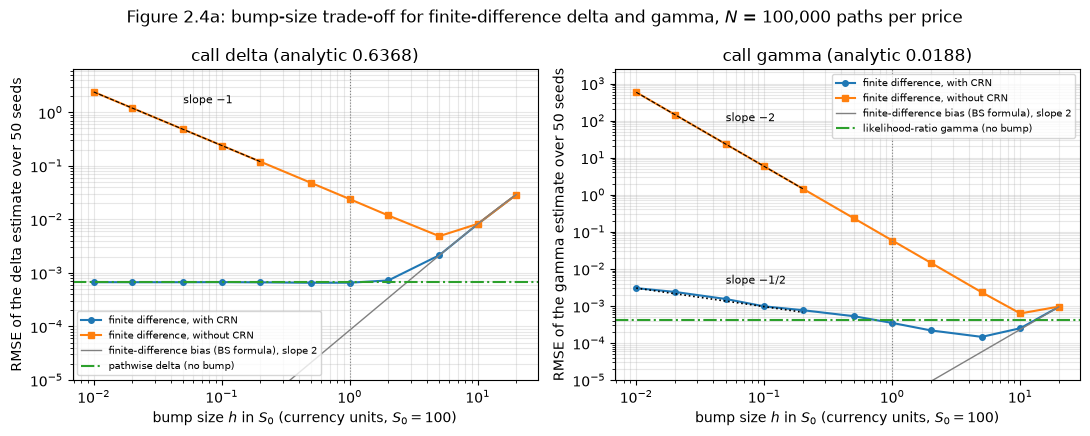

In [17]:
fig, (ax_d, ax_g) = plt.subplots(1, 2, figsize=(11, 4.4))
styles_2_4 = {'with CRN': ('o-', 'tab:blue'), 'without CRN': ('s-', 'tab:orange')}
for label, (rmse_delta, rmse_gamma) in bump_study.items():
    marker, colour = styles_2_4[label]
    ax_d.loglog(bump_sizes, rmse_delta, marker, color=colour, ms=4, label=f'finite difference, {label}')
    ax_g.loglog(bump_sizes, rmse_gamma, marker, color=colour, ms=4, label=f'finite difference, {label}')
ax_d.loglog(h_fine, fd_bias_delta, '-', color='grey', lw=1, label='finite-difference bias (BS formula), slope 2')
ax_g.loglog(h_fine, fd_bias_gamma, '-', color='grey', lw=1, label='finite-difference bias (BS formula), slope 2')
ax_d.axhline(pathwise_rmse, color='tab:green', ls='-.', label='pathwise delta (no bump)')
ax_g.axhline(lr_rmse, color='tab:green', ls='-.', label='likelihood-ratio gamma (no bump)')

# Reference slopes, anchored at the measured point for the smallest h
h_ref = bump_sizes[:5]
rmse_no_crn_delta, rmse_no_crn_gamma = bump_study['without CRN']
rmse_crn_gamma = bump_study['with CRN'][1]
ax_d.loglog(h_ref, rmse_no_crn_delta[0] * (h_ref / h_ref[0])**-1, 'k--', lw=0.8)
ax_g.loglog(h_ref, rmse_no_crn_gamma[0] * (h_ref / h_ref[0])**-2, 'k--', lw=0.8)
ax_g.loglog(h_ref, rmse_crn_gamma[0] * (h_ref / h_ref[0])**-0.5, 'k:', lw=1.2)
ax_d.text(h_ref[2], 3 * rmse_no_crn_delta[2], 'slope $-1$', fontsize=8)
ax_g.text(h_ref[2], 4 * rmse_no_crn_gamma[2], 'slope $-2$', fontsize=8)
ax_g.text(h_ref[2], 2.5 * rmse_crn_gamma[2], 'slope $-1/2$', fontsize=8)
for ax, name in ((ax_d, 'delta'), (ax_g, 'gamma')):
    ax.axvline(1.0, color='grey', lw=0.8, ls=':')
    ax.set_xlabel('bump size $h$ in $S_0$ (currency units, $S_0 = 100$)')
    ax.set_ylabel(f'RMSE of the {name} estimate over {M_bump} seeds')
    ax.set_title(f'call {name} (analytic {greeks_call[name]:.4f})')
    ax.grid(alpha=0.3, which='both')
    ax.set_ylim(1e-5, None)                                  # hide the bias curve below the noise floor
ax_d.legend(fontsize=7, loc='lower left')
ax_g.legend(fontsize=7, loc='upper right')
fig.suptitle('Figure 2.4a: bump-size trade-off for finite-difference delta and gamma, '
             f'$N$ = {n_paths_2_4:,} paths per price')
fig.tight_layout()
plt.show()


**Figures 2.4b and 2.4c: varying the data.** Here we see how the price responds as each input changes. In
Figure 2.4b we move one input at a time over a wide range, keeping the others at the sample values: $S_0$ from 60
to 140, $\sigma$ from 5% to 60%, $T - t$ from 0.05 to 3 years and $r$ from 0 to 10%. Each point is a Monte Carlo
price with its 95% confidence interval (seed `SEED`), and the curves are Black–Scholes. A greek is the slope of
one of these curves, so the dashed tangent at the sample point is drawn with the analytic greek as its slope:
delta in $S_0$, vega in $\sigma$, $-\Theta$ in $T$ and rho in $r$. The lower panels show the Monte Carlo error.
Figure 2.4c then estimates delta and gamma themselves at spot prices from 60 to 140 (central differences,
$h = 1$, CRN), with 95% intervals from $M = 20$ seeds at each spot.


102 Monte Carlo prices: 0 outside their 95% interval; largest |error|/SE = 1.04


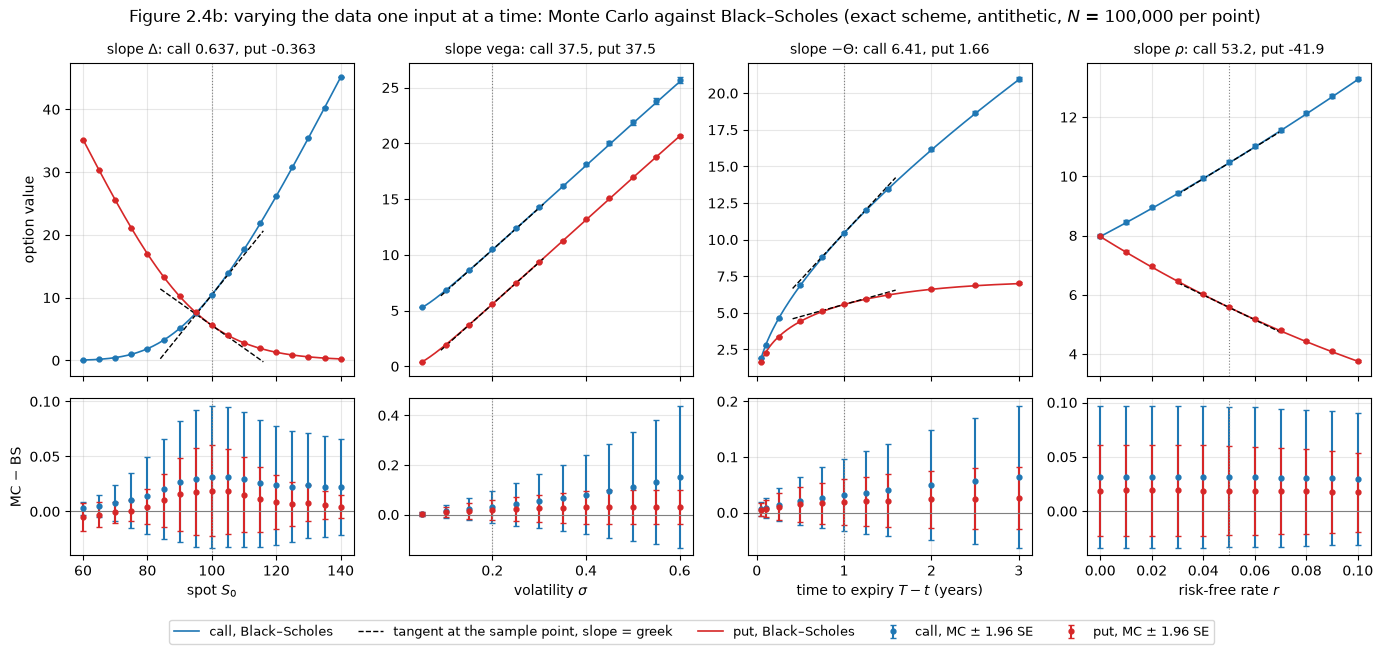

In [18]:
# Figure 2.4b: vary the data. Each input moves over its range with the others at the sample values;
# MC price (exact one-step scheme, antithetic, N = 100,000, seed SEED at every point) against Black-Scholes.
sample_inputs = dict(S0=S0, sigma=sigma, T=T, r=r)
input_ranges = {'S0': np.linspace(60, 140, 17), 'sigma': np.linspace(0.05, 0.60, 12),
                'T': np.array([0.05, 0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]),
                'r': np.linspace(0.0, 0.10, 11)}
# The slope of each price curve at the sample point is a greek: dV/dS0 = delta, dV/dsigma = vega,
# dV/dT = -theta (theta is dV/dt) and dV/dr = rho
slope_greek = {'S0': ('delta', 1), 'sigma': ('vega', 1), 'T': ('theta', -1), 'r': ('rho', 1)}
axis_labels = {'S0': 'spot $S_0$', 'sigma': r'volatility $\sigma$', 'T': 'time to expiry $T-t$ (years)',
               'r': 'risk-free rate $r$'}

vary_study = {}                                                    # (input, option) -> DataFrame of results
for name, values in input_ranges.items():
    for option in ('call', 'put'):
        rows_vary = []
        for value in values:
            inputs = dict(sample_inputs)                                # the sample data ...
            inputs[name] = value                                        # ... with one input changed
            price_vary, se_vary = mc_price(inputs['S0'], K, inputs['T'], inputs['r'], inputs['sigma'], n_paths_2_4, 1,
                                           'exact', option, np.random.default_rng(SEED), antithetic=True)
            bs_vary = bs_price(inputs['S0'], K, inputs['T'], inputs['r'], inputs['sigma'], option)
            rows_vary.append({'value': value, 'MC': price_vary, 'SE': se_vary, 'BS': bs_vary, 'error': price_vary - bs_vary})
        vary_study[name, option] = pd.DataFrame(rows_vary)

all_points = pd.concat(vary_study.values())
errors_in_se = all_points['error'].abs() / all_points['SE']
n_outside = int((errors_in_se > 1.96).sum())
print(f"{len(all_points)} Monte Carlo prices: {n_outside} outside their 95% interval; "
      f"largest |error|/SE = {errors_in_se.max():.2f}")

colours_2_4 = {'call': 'tab:blue', 'put': 'tab:red'}
greek_symbols = {'delta': r'\Delta', 'vega': r'\mathrm{vega}', 'theta': r'\Theta', 'rho': r'\rho'}
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharex='col', gridspec_kw={'height_ratios': [2, 1]})
for col, (name, values) in enumerate(input_ranges.items()):
    ax_price, ax_error = axes[0, col], axes[1, col]
    fine = np.linspace(values[0], values[-1], 200)
    inputs_fine = dict(sample_inputs)
    inputs_fine[name] = fine                                            # a fine grid for the Black-Scholes curve
    x0 = sample_inputs[name]
    greek, sign = slope_greek[name]
    slopes = {}
    for option in ('call', 'put'):
        colour, study = colours_2_4[option], vary_study[name, option]
        bs_curve = bs_price(inputs_fine['S0'], K, inputs_fine['T'], inputs_fine['r'], inputs_fine['sigma'], option)
        ax_price.plot(fine, bs_curve, '-', color=colour, lw=1.2, label=f'{option}, Black–Scholes')
        ax_price.errorbar(study['value'], study['MC'], yerr=1.96 * study['SE'], fmt='o', color=colour, ms=3.5,
                          capsize=2, label=f'{option}, MC ± 1.96 SE')
        # tangent at the sample point: its slope is the analytic greek
        slopes[option] = sign * bs_greeks(S0, K, T, r, sigma, option)[greek]
        half_width = 0.2 * (values[-1] - values[0])
        x_tan = np.array([x0 - half_width, x0 + half_width])
        V0 = bs_price(S0, K, T, r, sigma, option)
        ax_price.plot(x_tan, V0 + slopes[option] * (x_tan - x0), '--', color='black', lw=1,
                      label='tangent at the sample point, slope = greek' if option == 'call' else None)
        ax_error.errorbar(study['value'], study['error'], yerr=1.96 * study['SE'], fmt='o', color=colour, ms=3.5,
                          capsize=2)
    slope_name = ('-' if sign < 0 else '') + greek_symbols[greek]
    ax_price.set_title(f"slope ${slope_name}$: call {slopes['call']:.3g}, put {slopes['put']:.3g}", fontsize=10)
    ax_price.axvline(x0, color='grey', lw=0.8, ls=':')
    ax_error.axhline(0, color='grey', lw=0.8)
    ax_error.axvline(x0, color='grey', lw=0.8, ls=':')
    ax_error.set_xlabel(axis_labels[name])
    ax_price.grid(alpha=0.3)
    ax_error.grid(alpha=0.3)
axes[0, 0].set_ylabel('option value')
axes[1, 0].set_ylabel('MC − BS')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=5, fontsize=9)
fig.suptitle('Figure 2.4b: varying the data one input at a time: Monte Carlo against Black–Scholes '
             '(exact scheme, antithetic, $N$ = 100,000 per point)')
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


call: largest |error|/SE  delta 1.39   gamma 1.94   SE of gamma: 1.1% to 6.6% of the analytic value
put: largest |error|/SE  delta 1.42   gamma 1.94   SE of gamma: 1.1% to 6.6% of the analytic value
largest |gamma_call - gamma_put| over all spots: 1.1e-14


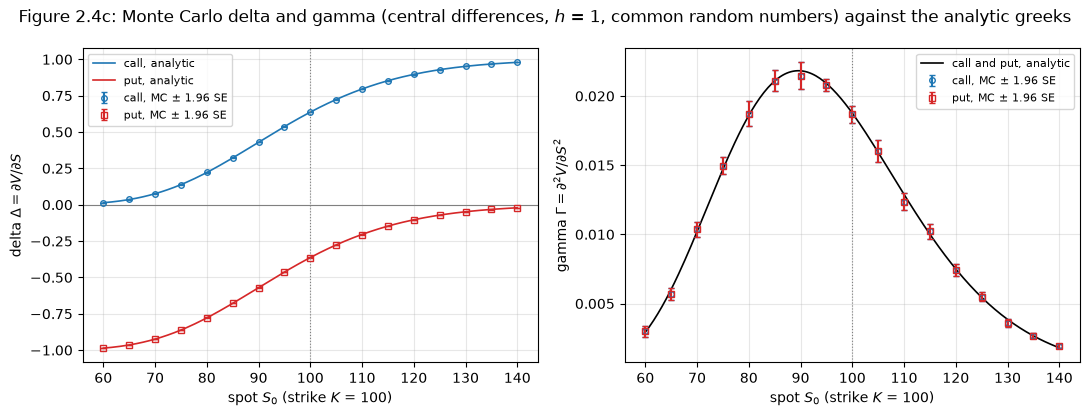

In [19]:
# Figure 2.4c: finite-difference delta and gamma (h = 1, common random numbers) against S0, call and put,
# with 95% intervals from M = 20 seeds per point, against the analytic curves of bs_greeks
spots_2_4 = np.linspace(60, 140, 17)
M_spot = 20
spot_study = {}
for option in ('call', 'put'):
    deltas_spot = np.zeros((len(spots_2_4), M_spot))                  # one row per spot, one column per seed
    gammas_spot = np.zeros((len(spots_2_4), M_spot))
    for i, spot in enumerate(spots_2_4):
        for m in range(M_spot):
            deltas_spot[i, m], gammas_spot[i, m] = fd_delta_gamma(spot, K, T, r, sigma, 1.0, n_paths_2_4, option, SEED + m)
    spot_study[option] = dict(delta=deltas_spot[:, 0], gamma=gammas_spot[:, 0],             # the seed-SEED run
                              delta_se=deltas_spot.std(axis=1, ddof=1), gamma_se=gammas_spot.std(axis=1, ddof=1))

for option in ('call', 'put'):
    analytic_spots = bs_greeks(spots_2_4, K, T, r, sigma, option)
    study = spot_study[option]
    delta_errors_in_se = np.abs(study['delta'] - analytic_spots['delta']) / study['delta_se']
    gamma_errors_in_se = np.abs(study['gamma'] - analytic_spots['gamma']) / study['gamma_se']
    gamma_relative_se = 100 * study['gamma_se'] / analytic_spots['gamma']          # % of the analytic gamma
    print(f"{option}: largest |error|/SE  delta {delta_errors_in_se.max():.2f}   gamma {gamma_errors_in_se.max():.2f}   "
          f"SE of gamma: {gamma_relative_se.min():.1f}% to {gamma_relative_se.max():.1f}% of the analytic value")
gamma_call_put_gap = np.max(np.abs(spot_study['call']['gamma'] - spot_study['put']['gamma']))
print(f"largest |gamma_call - gamma_put| over all spots: {gamma_call_put_gap:.1e}")

fig, (ax_d, ax_g) = plt.subplots(1, 2, figsize=(11, 4.2))
spot_fine = np.linspace(60, 140, 200)
for option, marker in (('call', 'o'), ('put', 's')):
    colour, study = colours_2_4[option], spot_study[option]
    analytic_fine = bs_greeks(spot_fine, K, T, r, sigma, option)
    ax_d.plot(spot_fine, analytic_fine['delta'], '-', color=colour, lw=1.2, label=f'{option}, analytic')
    ax_d.errorbar(spots_2_4, study['delta'], yerr=1.96 * study['delta_se'], fmt=marker, color=colour, ms=4,
                  capsize=2, mfc='none', label=f'{option}, MC ± 1.96 SE')
    if option == 'call':                                            # one analytic gamma serves the call and the put
        ax_g.plot(spot_fine, analytic_fine['gamma'], '-', color='black', lw=1.2, label='call and put, analytic')
    ax_g.errorbar(spots_2_4, study['gamma'], yerr=1.96 * study['gamma_se'], fmt=marker, color=colour, ms=4,
                  capsize=2, mfc='none', label=f'{option}, MC ± 1.96 SE')
for ax, label in ((ax_d, r'delta $\Delta = \partial V/\partial S$'), (ax_g, r'gamma $\Gamma = \partial^2 V/\partial S^2$')):
    ax.axvline(K, color='grey', lw=0.8, ls=':')
    ax.set_xlabel('spot $S_0$ (strike $K$ = 100)')
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
ax_d.axhline(0, color='grey', lw=0.8)
fig.suptitle('Figure 2.4c: Monte Carlo delta and gamma (central differences, $h$ = 1, common random numbers) '
             'against the analytic greeks')
fig.tight_layout()
plt.show()


**Reading the results.** Common random numbers make the Greeks much more precise (Table 2.4a).
Without them, standard errors are 11 to 847 times larger and some estimates have the wrong sign. At the
sample settings, finite-difference gamma has the largest relative SE, about 1.75%. Figure 2.4a shows its
bump-size trade-off: $h=5$ gives the lowest measured RMSE among the tested choices, whereas $h=1$ is already
close to the best tested choice for delta.

Across the input ranges, the simulated prices and spot sensitivities follow their Black–Scholes benchmarks
(Figures 2.4b–c). The price curves show the direction of each response; delta and gamma show how the spot
response changes. Section 3.2 discusses the shared-draw comparisons; the conclusion returns to their financial interpretation.
